In [1]:
import os
import random
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import optuna

os.environ["MLFLOW_ALLOW_FILE_STORE"] = "true"

PROJECT_ROOT = Path.cwd().parent
sys.path.append(str(PROJECT_ROOT))

from src.models.tcn_wrapper import TCNModel
from src.eval.scorer import VolatilityScorer
from src.trainer.walk_forward import WalkForwardTrainer

warnings.filterwarnings("ignore")

SEED = 42
os.environ["PYTHONHASHSEED"] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)

OUT_PATH = PROJECT_ROOT / "data" / "processed"
RESULTS_PATH = PROJECT_ROOT / "results" / "TCN"
RESULTS_PATH.mkdir(parents=True, exist_ok=True)

df_train = pd.read_parquet(OUT_PATH / "brent_train.parquet")
y_train = df_train["log_returns"].values.astype("float64")
rs_train = df_train["rs_daily"].values.astype("float64")

df_test = pd.read_parquet(OUT_PATH / "brent_test.parquet")
y_test = df_test["log_returns"].values.astype("float64")
rs_test = df_test["rs_daily"].values.astype("float64")

assert not np.isnan(y_train).any() and not np.isnan(rs_train).any()
assert not np.isnan(y_test).any() and not np.isnan(rs_test).any()

print("=" * 70)
print(f"Train: {len(y_train)} obs  ({df_train.index[0].date()} -> {df_train.index[-1].date()})")
print(f"Test:  {len(y_test)} obs  ({df_test.index[0].date()} -> {df_test.index[-1].date()})")
print("=" * 70)

Train: 2171 obs  (2014-01-03 -> 2022-11-03)
Test:  953 obs  (2022-11-07 -> 2026-08-21)


# Pruebas

In [2]:
import time
from src.eval.losses import QLIKELoss

scorer = VolatilityScorer()

# 1. Instanciamos el TCN con una configuración pequeña pero válida
model = TCNModel(
    look_back=14,
    num_levels=3,
    channels=16,
    kernel_size=2,
    num_convs=2,
    dropout=0.1,
    learning_rate=1e-3,
    weight_decay=1e-6,
    max_epochs=30,
    patience=5,
    batch_size=128,
    retrain_freq=10_000,
    target_scale=1e4,    
)

print(">> Iniciando fit del TCN ...")
t0 = time.time()
model.fit(y_train[:1000], rs_train[:1000])
print(f">> Fit OK en {time.time() - t0:.1f} s")
print("   diagnostics:", model.get_diagnostics())

>> Iniciando fit del TCN ...
>> Fit OK en 12.3 s
   diagnostics: {'converged': True, 'epochs_run': 12}


In [3]:
print(">> Iniciando forecast (10 días) ...")
t0 = time.time()
preds = model.forecast(y_test[:10], rs_test[:10])
print(f">> Forecast OK en {time.time() - t0:.1f} s")
print(f"   preds[:5] = {preds[:5]}")
print(f"   rango = [{preds.min():.3e}, {preds.max():.3e}]")

qlike = scorer.qlike(rs_test[:10], preds)
print(f">> QLIKE (10 días): {qlike:.4f}")

>> Iniciando forecast (10 días) ...
>> Forecast OK en 1.9 s
   preds[:5] = [0.00021579 0.000271   0.00027242 0.0002723  0.00027181]
   rango = [2.158e-04, 2.729e-04]
>> QLIKE (10 días): 0.4750


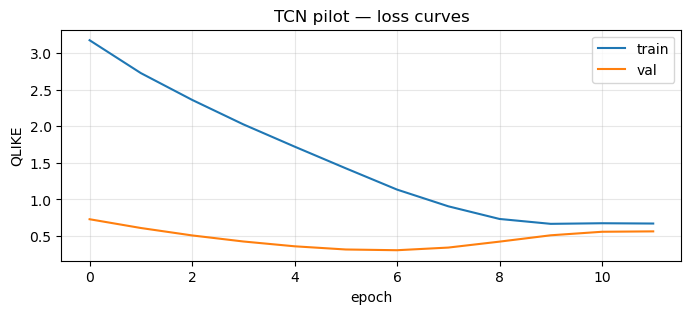

In [6]:
import matplotlib.pyplot as plt

hist = model.get_history()
plt.figure(figsize=(8, 3))
plt.plot(hist["train_loss"], label="train")
plt.plot(hist["val_loss"],   label="val")
plt.xlabel("epoch"); plt.ylabel("QLIKE"); plt.legend(); plt.grid(alpha=0.3)
plt.title("TCN pilot — loss curves")
plt.show()

In [5]:
FULL_DIR = RESULTS_PATH / "quick_test"
FULL_DIR.mkdir(parents=True, exist_ok=True)

def tcn_search_space_quick(trial: optuna.Trial) -> dict:
    return {
        "look_back": 14,
        "kernel_size": 2,
        "num_convs": 2,
        "num_levels": 3,
        "channels": 16,
        "dropout": 0.1,
        "learning_rate": 1e-3,
        "weight_decay": 1e-6,
        "max_epochs": 10,
        "patience": 5,
        "retrain_freq": 10,
        "target_scale": 1e4,
        "seed": 42,
    }

print("Iniciando TCN | PRUEBA RÁPIDA")

trainer = WalkForwardTrainer(
    model_class=TCNModel,
    scorer=scorer,
    output_dir=FULL_DIR,
    n_splits=1,
    warmup=800,
    embargo=1,
    suggest_params_fn=tcn_search_space_quick,
    n_trials=1,
    early_stop_rounds=None,
)

t0 = time.time()
trainer.run(y_train[:1000], rs_train[:1000])
print(f"Tiempo total: {(time.time() - t0) / 60:.2f} min")

Iniciando TCN | PRUEBA RÁPIDA


  0%|          | 0/1 [00:00<?, ?it/s]

Tiempo total: 0.86 min


In [3]:
import time
import optuna

# Usamos una carpeta temporal para no ensuciar los resultados reales
TEST_DIR = RESULTS_PATH / "tcn_explosion_test"
TEST_DIR.mkdir(parents=True, exist_ok=True)

# Recortamos los datos para que la prueba sea rapidísima
y_small = y_train[:500]
rs_small = rs_train[:500]

def tcn_test_space(trial: optuna.Trial) -> dict:
    return {
        "look_back": 14,
        "kernel_size": 2,
        "num_convs": 2,
        "num_levels": 4,
        "channels": 32,
        "dropout": 0.1,
        # OBLIGAMOS a Optuna a probar valores entre 1e-3 y 1e-2
        "learning_rate": trial.suggest_float("learning_rate", 1e-3, 1e-2, log=True),
        "weight_decay": 1e-6,
        "max_epochs": 5,           # Solo 5 épocas para ver si aguanta
        "patience": 2,
        "retrain_freq": 10000,     # Sin fine-tuning para que vuele
        "target_scale": 1e4,
        "seed": 42
    }

print("Iniciando prueba de explosión (Learning Rates altos)...")

trainer = WalkForwardTrainer(
    model_class=TCNModel,
    scorer=VolatilityScorer(),
    output_dir=TEST_DIR,
    n_splits=1,                   # Solo 1 fold
    warmup=400,
    embargo=1,
    suggest_params_fn=tcn_test_space,
    n_trials=3,                   # Solo 3 trials (uno con 1e-3, uno medio, uno con 1e-2)
    early_stop_rounds=None,
)

t0 = time.time()
trainer.run(y_small, rs_small)
print(f"Tiempo total de la prueba: {(time.time() - t0) / 60:.2f} min")

Iniciando prueba de explosión (Learning Rates altos)...


  0%|          | 0/3 [00:00<?, ?it/s]

Tiempo total de la prueba: 0.49 min


In [4]:
import time
import optuna

# Usamos una carpeta nueva para no mezclar con los datos viejos
TEST_DIR = RESULTS_PATH / "tcn_forense_test"
TEST_DIR.mkdir(parents=True, exist_ok=True)

def fixed_tcn_space(trial: optuna.Trial) -> dict:
    # Diccionario con los hiperparámetros exactos que fallaron antes
    configs = [
        # Config 1: El que tenía learning_rate altísimo (0.007) y num_levels=7
        {
            "look_back": 21, "kernel_size": 2, "num_convs": 1, "num_levels": 7, 
            "channels": 64, "dropout": 0.2597, "learning_rate": 0.00767, "weight_decay": 5.15e-06
        },
        # Config 2: El que tenía channels=128 y lr=0.00029
        {
            "look_back": 28, "kernel_size": 3, "num_convs": 1, "num_levels": 4, 
            "channels": 128, "dropout": 0.0194, "learning_rate": 0.00029, "weight_decay": 2.53e-05
        },
        # Config 3: El que tenía look_back=14 y num_convs=3
        {
            "look_back": 14, "kernel_size": 3, "num_convs": 3, "num_levels": 2, 
            "channels": 32, "dropout": 0.1866, "learning_rate": 0.00013, "weight_decay": 0.00023
        }
    ]
    
    # Extraemos la config según el trial (0, 1, o 2)
    params = configs[trial.number].copy()
    
    # Inyectamos las condiciones de entrenamiento (incluyendo el famoso target_scale)
    params.update({
        "max_epochs": 200,
        "patience": 20,
        "retrain_freq": 30,
        "target_scale": 1e4,  # <-- LA SOLUCIÓN AL NaN
        "seed": 42
    })
    return params

print("Iniciando prueba forense de los 3 trials fallidos (con 5 folds)...")

trainer = WalkForwardTrainer(
    model_class=TCNModel,
    scorer=VolatilityScorer(),
    output_dir=TEST_DIR,
    n_splits=5,                   # 5 folds completos (como en tu CSV original)
    warmup=1210,                  # Mismo warmup
    embargo=1,
    suggest_params_fn=fixed_tcn_space,
    n_trials=3,                   # Solo probamos esas 3 configuraciones
    early_stop_rounds=None,       # Queremos ver los 5 folds de cada una
)

t0 = time.time()
trainer.run(y_train, rs_train)  # <-- Usamos el dataset completo
print(f"Tiempo total de la prueba: {(time.time() - t0) / 60:.2f} min")

Iniciando prueba forense de los 3 trials fallidos (con 5 folds)...


  0%|          | 0/2 [00:00<?, ?it/s]

[W 2026-11-05 21:58:25,028] Trial 1 failed with parameters: {} because of the following error: KeyboardInterrupt().
Traceback (most recent call last):
  File "C:\Users\jcami\.conda\envs\brent-dl\lib\site-packages\optuna\study\_optimize.py", line 206, in _run_trial
    value_or_values = func(trial)
  File "C:\Users\jcami\Documents\brent-crude-nlp-market-dynamics\src\trainer\walk_forward.py", line 239, in <lambda>
    lambda trial: self.objective(trial, y, rs),
  File "C:\Users\jcami\Documents\brent-crude-nlp-market-dynamics\src\trainer\walk_forward.py", line 153, in objective
    preds = model.forecast(y_seq, rs_seq)
  File "C:\Users\jcami\Documents\brent-crude-nlp-market-dynamics\src\models\dl_base.py", line 257, in forecast
    loss = self.criterion(self.net(x_batch), y_batch)
  File "C:\Users\jcami\.conda\envs\brent-dl\lib\site-packages\torch\nn\modules\module.py", line 1778, in _wrapped_call_impl
    return self._call_impl(*args, **kwargs)
  File "C:\Users\jcami\.conda\envs\brent-dl

KeyboardInterrupt: 

# ENTRENAMIENTO

In [ ]:
import math
import time
import optuna

FULL_DIR = RESULTS_PATH / "tcn_full_run" 
FULL_DIR.mkdir(parents=True, exist_ok=True)

def tcn_search_space(trial: optuna.Trial) -> dict:
    look_back = trial.suggest_categorical("look_back", [7, 14, 21, 28])
    kernel_size = trial.suggest_categorical("kernel_size", [2, 3])
    num_convs = trial.suggest_categorical("num_convs", [1, 2, 3])
    
    min_levels = math.ceil(
        math.log2(1 + (look_back - 1) / (num_convs * (kernel_size - 1)))
    )
    
    return {
        "look_back": look_back,
        "kernel_size": kernel_size,
        "num_convs": num_convs,
        "num_levels": trial.suggest_int("num_levels", min_levels, min_levels + 2),
        "channels": trial.suggest_categorical("channels", [32, 64, 128]),
        "dropout": trial.suggest_float("dropout", 0.0, 0.3),            
        "learning_rate": trial.suggest_float("learning_rate", 1e-4, 1e-2, log=True),
        "weight_decay": trial.suggest_float("weight_decay", 1e-6, 1e-3, log=True),
        "max_epochs": 200,
        "patience": 20,
        "retrain_freq": 1,
        "target_scale": 1e4, 
        "seed": 42
    }

current_warmup = 1210
print(f"Iniciando TCN | Ejecución Única | warmup={current_warmup}")

trainer = WalkForwardTrainer(
    model_class=TCNModel,
    scorer=VolatilityScorer(),
    output_dir=FULL_DIR,
    n_splits=5,
    warmup=current_warmup,
    embargo=1,
    suggest_params_fn=tcn_search_space,
    n_trials=50,
    early_stop_rounds=15
)

t0 = time.time()
trainer.run(y_train, rs_train)
print(f"Tiempo total: {(time.time() - t0) / 60:.1f} min")